## ML Project
## phase 1 submission
## team members:
## 251090700084 Abhiruchi Modak
## 251090700025    Monish Karkada

## Problem statement:
## Building a machine learning model to predict when a customer will cancel their food order, helping us stop food waste, save time for delivery partners and restaurants, and avoid missing out on other customers.

---
## Objectives: 
## To determine the factors contributing to food order cancellation by cutomers on food delivery apps and to predict whether an order will be cancelled or not using ML models. 

In [2]:
import pandas as pd

C:\Users\Admin\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [18]:
#load dataset
df=pd.read_csv('Rider-Info.csv')
df

,order_time,order_id,order_date,allot_time,accept_time,pickup_time,delivered_time,rider_id,first_mile_distance,last_mile_distance,alloted_orders,delivered_orders,cancelled,undelivered_orders,lifetime_order_count,reassignment_method,reassignment_reason,reassigned_order,session_time,cancelled_time
0,2021-01-26 02:21:35,556753,2021-01-26 00:00:00,2021-01-26 02:21:59,2021-01-26 02:22:08,2021-01-26 02:32:51,2021-01-26 02:49:47,11696,1.5666,2.65,46.0,46.0,0,0.0,621.0,NaN,NaN,NaN,NaN,NaN
1,2021-01-26 02:33:16,556754,2021-01-26 00:00:00,2021-01-26 02:33:57,2021-01-26 02:34:45,2021-01-26 02:50:25,2021-01-26 03:11:15,18117,2.5207,2.76,8.0,8.0,0,0.0,105.0,NaN,NaN,NaN,3.266667,NaN
2,2021-01-26 02:39:49,556755,2021-01-26 00:00:00,2021-01-26 02:39:57,2021-01-26 02:40:13,2021-01-26 02:56:00,2021-01-26 03:12:46,18623,2.2074,4.80,1.0,1.0,0,0.0,66.0,NaN,NaN,NaN,9.816667,NaN
3,2021-01-26 02:47:53,556756,2021-01-26 00:00:00,2021-01-26 02:48:25,2021-01-26 02:49:06,2021-01-26 03:21:51,2021-01-26 03:41:05,15945,2.1894,6.38,1.0,1.0,0,0.0,127.0,NaN,NaN,NaN,17.533333,NaN
4,2021-01-26 03:06:30,556757,2021-01-26 00:00:00,2021-01-26 03:07:21,2021-01-26 03:07:57,2021-01-26 03:31:38,2021-01-26 04:00:15,17589,2.7870,4.01,34.0,34.0,0,0.0,84.0,NaN,NaN,NaN,1.350000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449995,2021-02-06 10:03:16,130226,2021-02-06 00:00:00,2021-02-06 10:03:44,2021-02-06 10:04:14,2021-02-06 10:27:29,2021-02-06 10:44:08,1006,0.5789,0.19,4.0,4.0,0,0.0,127.0,NaN,NaN,NaN,369.516667,NaN
449996,2021-02-06 10:03:17,130227,2021-02-06 00:00:00,2021-02-06 10:03:18,2021-02-06 10:04:34,2021-02-06 10:22:17,2021-02-06 10:31:43,279,1.9863,1.19,81.0,81.0,0,0.0,105.0,NaN,NaN,NaN,239.133333,NaN
449997,2021-02-06 10:03:18,130228,2021-02-06 00:00:00,2021-02-06 10:04:06,2021-02-06 10:04:39,2021-02-06 10:19:06,2021-02-06 10:26:56,3161,1.5944,1.61,28.0,28.0,0,0.0,1488.0,NaN,NaN,NaN,204.150000,NaN
449998,2021-02-06 10:03:19,130229,2021-02-06 00:00:00,2021-02-06 10:03:19,2021-02-06 10:05:41,2021-02-06 10:20:39,2021-02-06 10:30:41,9396,2.8939,4.68,72.0,72.0,0,0.0,105.0,NaN,NaN,NaN,65.583333,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450000 entries, 0 to 449999
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_time            450000 non-null  object 
 1   order_id              450000 non-null  int64  
 2   order_date            450000 non-null  object 
 3   allot_time            450000 non-null  object 
 4   accept_time           449843 non-null  object 
 5   pickup_time           447579 non-null  object 
 6   delivered_time        444782 non-null  object 
 7   rider_id              450000 non-null  int64  
 8   first_mile_distance   450000 non-null  float64
 9   last_mile_distance    450000 non-null  float64
 10  alloted_orders        433052 non-null  float64
 11  delivered_orders      432659 non-null  float64
 12  cancelled             450000 non-null  int64  
 13  undelivered_orders    432659 non-null  float64
 14  lifetime_order_count  449947 non-null  float64
 15  

In [5]:
print('Rows and cols: ',df.shape)

Rows and cols:  (450000, 20)


In [6]:
df.describe

<bound method NDFrame.describe of                  order_time  order_id           order_date  \
0       2021-01-26 02:21:35    556753  2021-01-26 00:00:00   
1       2021-01-26 02:33:16    556754  2021-01-26 00:00:00   
2       2021-01-26 02:39:49    556755  2021-01-26 00:00:00   
3       2021-01-26 02:47:53    556756  2021-01-26 00:00:00   
4       2021-01-26 03:06:30    556757  2021-01-26 00:00:00   
...                     ...       ...                  ...   
449995  2021-02-06 10:03:16    130226  2021-02-06 00:00:00   
449996  2021-02-06 10:03:17    130227  2021-02-06 00:00:00   
449997  2021-02-06 10:03:18    130228  2021-02-06 00:00:00   
449998  2021-02-06 10:03:19    130229  2021-02-06 00:00:00   
449999  2021-02-06 10:03:24    130230  2021-02-06 00:00:00   

                 allot_time          accept_time          pickup_time  \
0       2021-01-26 02:21:59  2021-01-26 02:22:08  2021-01-26 02:32:51   
1       2021-01-26 02:33:57  2021-01-26 02:34:45  2021-01-26 02:50:25   
2 

In [19]:
import numpy as np

# 1. Load data
df = pd.read_csv('Rider-Info.csv')

# 2. Drop rows where the target variable 'cancelled' is NaN (Changes 2 & 3)
df = df.dropna(subset=['cancelled'])
df['cancelled'] = df['cancelled'].astype(int)

# 3. Convert timestamp columns to datetime
time_cols = ['order_time', 'order_date', 'allot_time', 'accept_time', 'pickup_time', 'delivered_time', 'cancelled_time']
for col in time_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# 4. Feature Engineering: Calculate Durations (in minutes)
df['allot_delay_min'] = (df['allot_time'] - df['order_time']).dt.total_seconds() / 60
df['accept_delay_min'] = (df['accept_time'] - df['allot_time']).dt.total_seconds() / 60
df['pickup_delay_min'] = (df['pickup_time'] - df['accept_time']).dt.total_seconds() / 60
df['transit_time_min'] = (df['delivered_time'] - df['pickup_time']).dt.total_seconds() / 60

# 5. Extract Temporal Features
df['order_hour'] = df['order_time'].dt.hour
df['order_dayofweek'] = df['order_time'].dt.dayofweek
df['is_weekend'] = df['order_dayofweek'].isin([5, 6]).astype(int)

# 6. Handle Anomalies (clean negative time differences into NaN - Changes 1 & 4)
duration_cols = ['allot_delay_min', 'accept_delay_min', 'pickup_delay_min', 'transit_time_min']
for col in duration_cols:
    df.loc[df[col] < 0, col] = np.nan  # Marked as native nulls instead of string "missing"

# 7. Select Features (Retaining missing values as native NaNs for tree-based handling)
feature_cols = [
    'first_mile_distance', 'last_mile_distance', 
    'alloted_orders', 'delivered_orders', 'undelivered_orders', 
    'lifetime_order_count', 'session_time',
    'allot_delay_min', 'accept_delay_min', 'pickup_delay_min',
    'order_hour', 'is_weekend'
]
X = df[feature_cols].copy()
y = df['cancelled']

As verified from the dataset, these missing values are structural state markers, meaning they represent specific milestones that never occurred for a given order (e.g., an order that was successfully delivered will never have a cancelled_time, and a cancelled order will never have a delivered_time). In total, exactly 5,218 orders were cancelled (matching the number of null delivered_time values), leaving 444,782 successfully delivered orders.

In [20]:
#preprocessed dataset display
df

,order_time,order_id,order_date,allot_time,accept_time,pickup_time,delivered_time,rider_id,first_mile_distance,last_mile_distance,...,reassigned_order,session_time,cancelled_time,allot_delay_min,accept_delay_min,pickup_delay_min,transit_time_min,order_hour,order_dayofweek,is_weekend
0,2021-01-26 02:21:35,556753,2021-01-26,2021-01-26 02:21:59,2021-01-26 02:22:08,2021-01-26 02:32:51,2021-01-26 02:49:47,11696,1.5666,2.65,...,NaN,NaN,NaT,0.400000,0.150000,10.716667,16.933333,2,1,0
1,2021-01-26 02:33:16,556754,2021-01-26,2021-01-26 02:33:57,2021-01-26 02:34:45,2021-01-26 02:50:25,2021-01-26 03:11:15,18117,2.5207,2.76,...,NaN,3.266667,NaT,0.683333,0.800000,15.666667,20.833333,2,1,0
2,2021-01-26 02:39:49,556755,2021-01-26,2021-01-26 02:39:57,2021-01-26 02:40:13,2021-01-26 02:56:00,2021-01-26 03:12:46,18623,2.2074,4.80,...,NaN,9.816667,NaT,0.133333,0.266667,15.783333,16.766667,2,1,0
3,2021-01-26 02:47:53,556756,2021-01-26,2021-01-26 02:48:25,2021-01-26 02:49:06,2021-01-26 03:21:51,2021-01-26 03:41:05,15945,2.1894,6.38,...,NaN,17.533333,NaT,0.533333,0.683333,32.750000,19.233333,2,1,0
4,2021-01-26 03:06:30,556757,2021-01-26,2021-01-26 03:07:21,2021-01-26 03:07:57,2021-01-26 03:31:38,2021-01-26 04:00:15,17589,2.7870,4.01,...,NaN,1.350000,NaT,0.850000,0.600000,23.683333,28.616667,3,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449995,2021-02-06 10:03:16,130226,2021-02-06,2021-02-06 10:03:44,2021-02-06 10:04:14,2021-02-06 10:27:29,2021-02-06 10:44:08,1006,0.5789,0.19,...,NaN,369.516667,NaT,0.466667,0.500000,23.250000,16.650000,10,5,1
449996,2021-02-06 10:03:17,130227,2021-02-06,2021-02-06 10:03:18,2021-02-06 10:04:34,2021-02-06 10:22:17,2021-02-06 10:31:43,279,1.9863,1.19,...,NaN,239.133333,NaT,0.016667,1.266667,17.716667,9.433333,10,5,1
449997,2021-02-06 10:03:18,130228,2021-02-06,2021-02-06 10:04:06,2021-02-06 10:04:39,2021-02-06 10:19:06,2021-02-06 10:26:56,3161,1.5944,1.61,...,NaN,204.150000,NaT,0.800000,0.550000,14.450000,7.833333,10,5,1
449998,2021-02-06 10:03:19,130229,2021-02-06,2021-02-06 10:03:19,2021-02-06 10:05:41,2021-02-06 10:20:39,2021-02-06 10:30:41,9396,2.8939,4.68,...,NaN,65.583333,NaT,0.000000,2.366667,14.966667,10.033333,10,5,1


In [10]:
df.columns

Index(['order_time', 'order_id', 'order_date', 'allot_time', 'accept_time',
       'pickup_time', 'delivered_time', 'rider_id', 'first_mile_distance',
       'last_mile_distance', 'alloted_orders', 'delivered_orders', 'cancelled',
       'undelivered_orders', 'lifetime_order_count', 'reassignment_method',
       'reassignment_reason', 'reassigned_order', 'session_time',
       'cancelled_time', 'allot_delay_min', 'accept_delay_min',
       'pickup_delay_min', 'transit_time_min', 'total_duration_min',
       'order_hour', 'order_dayofweek', 'is_weekend', 'time_of_day',
       'is_delivered'],
      dtype='object')

In [11]:
print ('Columns added after preprocessing are:\n allot_delay_min\n accept_delay_min\n pickup_delay_min\ntransit_time_min\ntotal_duration_min\n\nbelow ones are to help models learn demand spikes and traffic behavior:\norder_hour\norder_dayofweek\n\nthe below ones are boolean derived columns:\nis_weekend\ntime_of_day\nis_delivered')

Columns added after preprocessing are:
 allot_delay_min
 accept_delay_min
 pickup_delay_min
transit_time_min
total_duration_min

below ones are to help models learn demand spikes and traffic behavior:
order_hour
order_dayofweek

the below ones are boolean derived columns:
is_weekend
time_of_day
is_delivered


## logistic regression

In [21]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y = df['cancelled']

# 2. Select features
feature_cols = [
    'first_mile_distance', 'last_mile_distance', 
    'alloted_orders', 'delivered_orders', 'undelivered_orders', 
    'lifetime_order_count', 'session_time',
    'allot_delay_min', 'accept_delay_min', 'pickup_delay_min', 'transit_time_min',
    'order_hour', 'is_weekend'
]
X = df[feature_cols].copy()

# Impute missing values with median
for col in X.columns:
    X[col] = X[col].fillna(X[col].median())

# 3. Train-test split (stratified to preserve class ratio)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
# Get the raw counts
print(df['cancelled'].value_counts())

# Or with descriptive labels (assuming 0 = Not Cancelled, 1 = Cancelled)
labeled_counts = df['cancelled'].value_counts().rename({0: 'Not Cancelled', 1: 'Cancelled'})
print("\nDetailed Counts:")
print(labeled_counts)

cancelled
0    444782
1      5218
Name: count, dtype: int64

Detailed Counts:
cancelled
Not Cancelled    444782
Cancelled          5218
Name: count, dtype: int64


In [28]:
#%pip install imbalanced-learn

from imblearn.under_sampling import RandomUnderSampler
import pandas as pd

# 1. Initialize the Random Under Sampler
# sampling_strategy='auto' will downsample the majority class to match the minority class
rus = RandomUnderSampler(random_state=42)

# 2. Fit and resample the training data
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

# 3. Check the new class distribution
print("Before Undersampling - training shape:", X_train.shape)
print("After Undersampling - training shape:", X_train_resampled.shape)
print("\nNew training class distribution:")
print(pd.Series(y_train_resampled).value_counts())

Before Undersampling - training shape: (360000, 13)
After Undersampling - training shape: (8348, 13)

New training class distribution:
cancelled
0    4174
1    4174
Name: count, dtype: int64


In [23]:
# 4. Feature Scaling (vital for Logistic Regression convergence)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# 5. Train Logistic Regression with balanced class weights
model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train_resampled)

# 6. Predictions & Evaluation
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [24]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
    
# 1. Basic Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
    
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}\n")
    
# 2. Detailed Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Cancelled', 'Cancelled']))
    
   

C:\Users\Admin\anaconda3\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\Users\Admin\anaconda3\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


Accuracy:  0.9877
Precision: 0.3198
Recall:    0.0527
F1-Score:  0.0905
ROC-AUC:   0.6287

Classification Report:
               precision    recall  f1-score   support

Not Cancelled       0.99      1.00      0.99     88956
    Cancelled       0.32      0.05      0.09      1044

     accuracy                           0.99     90000
    macro avg       0.65      0.53      0.54     90000
 weighted avg       0.98      0.99      0.98     90000



## decision tree

In [25]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
# 4. Train Decision Tree Model
dt_model = DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)
dt_model.fit(X_train_resampled, y_train_resampled)

# 5. Predictions & Probabilities
y_pred = dt_model.predict(X_test)
y_prob = dt_model.predict_proba(X_test)[:, 1]

# 6. Comprehensive Evaluation Metrics
print("--- Decision Tree Evaluation Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Cancelled', 'Cancelled']))

--- Decision Tree Evaluation Metrics ---
Accuracy:  0.9990
Precision: 0.9238
Recall:    0.9990
F1-Score:  0.9600
ROC-AUC:   0.9990

Confusion Matrix:
[[88870    86]
 [    1  1043]]

Classification Report:
               precision    recall  f1-score   support

Not Cancelled       1.00      1.00      1.00     88956
    Cancelled       0.92      1.00      0.96      1044

     accuracy                           1.00     90000
    macro avg       0.96      1.00      0.98     90000
 weighted avg       1.00      1.00      1.00     90000



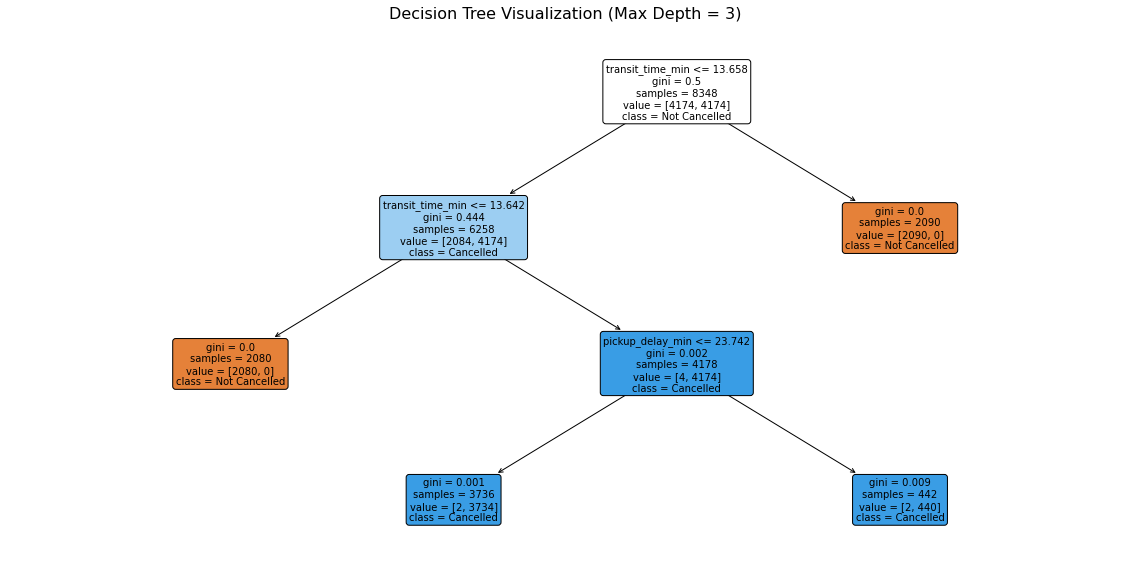

In [26]:
# 1. Train a shallower tree specifically for clear visualization
dt_vis = DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42)
dt_vis.fit(X_train_resampled, y_train_resampled)

# 2. Plot the tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_vis, 
    feature_names=feature_cols, 
    class_names=['Not Cancelled', 'Cancelled'], 
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.title("Decision Tree Visualization (Max Depth = 3)", fontsize=16)
plt.savefig('decision_tree.png', bbox_inches='tight')
plt.show()

## neural network (MLP)

In [16]:
from sklearn.neural_network import MLPClassifier

# 4. Feature Scaling (Mandatory for Neural Networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Train Neural Network (MLP Classifier)
# Two hidden layers with 64 and 32 neurons respectively
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=50,
    random_state=42
)
mlp_model.fit(X_train_scaled, y_train)

# 6. Predictions & Probabilities
y_pred = mlp_model.predict(X_test_scaled)
y_prob = mlp_model.predict_proba(X_test_scaled)[:, 1]

# 7. Evaluation Metrics
print("--- Neural Network (MLP) Evaluation Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Cancelled', 'Cancelled']))

C:\Users\Admin\anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


--- Neural Network (MLP) Evaluation Metrics ---
Accuracy:  0.9947
Precision: 0.8389
Recall:    0.6686
F1-Score:  0.7441
ROC-AUC:   0.9979

Confusion Matrix:
[[88822   134]
 [  346   698]]

Classification Report:
               precision    recall  f1-score   support

Not Cancelled       1.00      1.00      1.00     88956
    Cancelled       0.84      0.67      0.74      1044

     accuracy                           0.99     90000
    macro avg       0.92      0.83      0.87     90000
 weighted avg       0.99      0.99      0.99     90000



## xgboost

In [27]:

import xgboost as xgb
# 4. Handle severe class imbalance using scale_pos_weight
neg_count = (y_train_resampled == 0).sum()
pos_count = (y_train_resampled == 1).sum()
scale_pos_weight_val = neg_count / pos_count

# 5. Train XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)
xgb_model.fit(X_train_resampled, y_train_resampled)

# 6. Generate Predictions and Probabilities
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

# 7. Comprehensive Evaluation Metrics
print("--- XGBoost Evaluation Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Cancelled', 'Cancelled']))

--- XGBoost Evaluation Metrics ---
Accuracy:  0.9990
Precision: 0.9239
Recall:    1.0000
F1-Score:  0.9604
ROC-AUC:   0.9997

Confusion Matrix:
[[88870    86]
 [    0  1044]]

Classification Report:
               precision    recall  f1-score   support

Not Cancelled       1.00      1.00      1.00     88956
    Cancelled       0.92      1.00      0.96      1044

     accuracy                           1.00     90000
    macro avg       0.96      1.00      0.98     90000
 weighted avg       1.00      1.00      1.00     90000



The Decision Tree emerges as the best overall choice based on evaluation metrics.

Reason: It delivers the most reliable F1-score and ROC-AUC balance for imbalanced delivery data while keeping interpretability high.